# Window Insertion vs the fixed-route family

`WindowInsertionPolicy` is the first policy here to keep a **persistent
schedule** across planning calls, and the first to enforce a **hard pickup
deadline**. This notebook checks it against the two policies it has to beat:

- **`FixedRoutePolicy`** — the schedule-following baseline, cycling every stop
  in a fixed order regardless of demand.
- **`SkipStopFixedRoutePolicy`** — our previous leader whenever ride time
  mattered. It follows the same cycle but skips stops with no demand, which
  keeps the cycle's structural ride cap while cutting dead mileage.

The interesting knob is the **service window**: a request is accepted only if
the bus can reach its pickup within `max_wait_s` seconds of the request being
made. Requests that cannot be served in time are rejected outright (a *soft
skip* — they stay `PENDING` and remain eligible for a later plan) rather than
served arbitrarily late.

**What this notebook covers:**
1. Generating the shared campus map
2. Sweeping the service window against both baselines
3. The coverage/wait-tail frontier the window traces out
4. Aggregate KPI bars and wait-time distributions

## Why the window should matter

Fixed routes are hard to beat for a structural reason rather than a clever
one: a bus that cycles visits every stop within a bounded period, so the
worst-case wait is bounded for free. Demand-responsive policies have no such
guarantee — they chase whatever is convenient and strand the awkward requests,
which is why they historically lost on the metrics that punish tails.

A service window buys that guarantee back without cycling. The sweep below
should show the trade directly: **tighter windows** reject more but protect the
wait tail, **looser windows** accept more and let the tail grow.

In [1]:
%matplotlib inline
# Static comparison charts only, so the inline backend is all we need.

import statistics

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src.algorithm.FixedRoutePolicy import FixedRoutePolicy
from src.algorithm.SkipStopFixedRoutePolicy import SkipStopFixedRoutePolicy
from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy
from src.experiment import (
    plot_kpi_bars,
    plot_wait_distribution,
    summarize_comparison,
)
from src.map.PlanarMapProvider import PlanarMapProvider
from src.map.graph import PlanarStreetGraph

## 1. Shared map

The campus configuration used by the other sweep notebooks (2km square, 17
seeds, `stop_density=0.5`), so results here line up with the `ride_factor` and
`detour_factor` sweeps.

As always there are two independent seeds: `MAP_SEED` fixes the road network
and stop placement, while the per-trial seed controls only the demand
sequence, so every policy replays identical requests.

In [2]:
MAP_SEED = 42

graph = PlanarStreetGraph.generate(
    n_seeds=17,
    bounds=(0.0, 0.0, 2000.0, 2000.0),
    seed=MAP_SEED,
    stop_density=0.5,
)

provider = PlanarMapProvider(graph)
print(f"{len(provider.get_stops())} bus stops on this map")

21 bus stops on this map


## 2. Sweeping the service window

Each swept window is its own column, alongside the two baselines and a
**no-window** column. That last one is the ablation: it is the same persistent
insertion machinery with the deadline test switched off, so the gap between it
and the windowed columns is precisely what the windows contribute — as opposed
to what the insertion scheduling contributes on its own.

`max_wait_s=900.0` in `TRIAL_KWARGS` is the **simulation's** abandonment
threshold: how long a passenger waits before giving up. The policy's window is
a separate number — its own service promise. Setting the window at or below
the abandonment threshold gives a real guarantee: no *accepted* request is
ever abandoned. That is why the sweep tops out at 900.

> ⚠️ **The two `max_wait_s` values are not linked in code.** A window looser
> than the abandonment threshold silently voids that guarantee, so vary them
> deliberately.

### A note on runtime

`WindowInsertionPolicy` is far more expensive per trial than the fixed-route
family — it evaluates every (pickup slot, dropoff slot) pair against a
persistent schedule, so cost grows steeply with the number of live requests.
At 200 requests expect roughly **1.4s per trial** against ~0.03s for the
baselines, i.e. about 12 minutes for the cell below. Drop `N_TRIALS` if you
just want a quick look.

In [3]:
# Swept service windows in seconds (edit freely). 900 matches the simulation's
# abandonment threshold, which is the widest window that still guarantees no
# accepted request is ever abandoned.
WINDOWS = [450.0, 600.0, 750.0, 900.0]

# Stands in for "no window at all" — large enough that the deadline never
# binds, isolating what persistent insertion alone achieves.
NO_WINDOW = 1e9

N_TRIALS = 100
BASE_SEED = 0

# run_trial kwargs, matching the campus experiment.
TRIAL_KWARGS = dict(max_requests=200, capacity=40, max_wait_s=900.0)

# Baselines plus the ablation plus one column per swept window. The `w=w`
# default-arg capture avoids the late-binding closure bug.
policies = [
    ("Fixed route", lambda g: FixedRoutePolicy(g)),
    ("Fixed route w/ skip", lambda g: SkipStopFixedRoutePolicy(g)),
    (
        "Insertion (no window)",
        lambda g: WindowInsertionPolicy(g, max_wait_s=NO_WINDOW),
    ),
] + [
    (
        f"Window {int(w)}s",
        lambda g, w=w: WindowInsertionPolicy(g, max_wait_s=w),
    )
    for w in WINDOWS
]

summary = summarize_comparison(
    policies=policies,
    graph=graph,
    n_trials=N_TRIALS,
    base_seed=BASE_SEED,
    **TRIAL_KWARGS,
)

display(Markdown(summary.markdown))

Fixed route          :   0%|          | 0/100 [00:00<?, ?it/s]

Fixed route w/ skip  :   0%|          | 0/100 [00:00<?, ?it/s]

Insertion (no window):   0%|          | 0/100 [00:00<?, ?it/s]

Window 450s          :   0%|          | 0/100 [00:00<?, ?it/s]

Window 600s          :   0%|          | 0/100 [00:00<?, ?it/s]

Window 750s          :   0%|          | 0/100 [00:00<?, ?it/s]

Window 900s          :   0%|          | 0/100 [00:00<?, ?it/s]

| Property | Fixed route | Fixed route w/ skip | Insertion (no window) | Window 450s | Window 600s | Window 750s | Window 900s |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Fulfilled requests | 129.4 (±1.1%) | 131.3 (±3.0%) | 158.2 (±2.1%) | 147.0 (±2.3%) | 165.4 (±2.2%) | 177.1 (±2.1%) | 181.2 (±2.0%) |
| Cancelled requests | 70.6 (±2.0%) | 64.7 (±3.5%) | 39.9 (±3.5%) | 51.0 (±3.8%) | 32.6 (±4.7%) | 20.9 (±5.0%) | 16.8 (±5.5%) |
| Mean wait time | 446.6 s (±1.1%) | 461.0 s (±2.9%) | 413.6 s (±2.1%) | 353.0 s (±2.1%) | 400.7 s (±2.1%) | 446.9 s (±2.1%) | 494.4 s (±2.1%) |
| P90 wait time | 799.0 s (±0.6%) | 795.1 s (±2.9%) | 747.3 s (±2.1%) | 551.9 s (±2.9%) | 585.6 s (±2.0%) | 722.0 s (±2.0%) | 850.1 s (±2.0%) |
| Mean ride time | 693.9 s (±0.9%) | 616.8 s (±3.0%) | 361.9 s (±2.4%) | 822.6 s (±3.3%) | 778.3 s (±3.4%) | 630.7 s (±3.0%) | 541.2 s (±3.0%) |
| Fulfillment rate | 64.7 % (±1.1%) | 67.7 % (±1.7%) | 80.1 % (±0.9%) | 74.5 % (±1.3%) | 83.7 % (±0.9%) | 89.6 % (±0.6%) | 91.6 % (±0.5%) |
| Served fraction | 64.7 % (±1.1%) | 67.7 % (±1.7%) | 80.1 % (±0.9%) | 74.5 % (±1.3%) | 83.7 % (±0.9%) | 89.6 % (±0.6%) | 91.6 % (±0.5%) |
| Throughput | 0.6 req/min (±1.1%) | 0.7 req/min (±13.5%) | 0.8 req/min (±2.6%) | 0.7 req/min (±3.0%) | 0.8 req/min (±2.5%) | 0.8 req/min (±2.1%) | 0.8 req/min (±2.1%) |
| Tick snapshots | 13407.2 (±0.4%) | 12933.2 (±2.9%) | 12810.2 (±2.0%) | 12914.9 (±2.0%) | 13011.2 (±2.0%) | 13046.8 (±2.0%) | 13091.7 (±2.0%) |
| Fulfilled (wait samples) | 129.4 (±1.1%) | 131.3 (±3.0%) | 158.2 (±2.1%) | 147.0 (±2.3%) | 165.4 (±2.2%) | 177.1 (±2.1%) | 181.2 (±2.0%) |
| Min wait time | 8.6 s (±19.4%) | 7.5 s (±19.5%) | 7.2 s (±24.0%) | 6.8 s (±20.3%) | 7.2 s (±20.6%) | 6.1 s (±21.5%) | 7.2 s (±23.8%) |
| Max wait time | 892.5 s (±0.2%) | 875.5 s (±2.8%) | 880.8 s (±2.0%) | 864.8 s (±2.1%) | 854.2 s (±2.1%) | 856.2 s (±2.1%) | 888.4 s (±2.0%) |
| Min ride time | 11.0 s (±18.2%) | 10.6 s (±13.4%) | 6.5 s (±11.0%) | 7.8 s (±12.8%) | 7.7 s (±13.7%) | 6.6 s (±12.6%) | 7.4 s (±14.3%) |
| Max ride time | 1377.6 s (±0.1%) | 1349.2 s (±2.9%) | 1572.4 s (±4.0%) | 4037.1 s (±4.6%) | 4127.0 s (±5.6%) | 3307.0 s (±4.8%) | 2765.3 s (±5.2%) |

## 3. The frontier

Two plots, because the window trades along two different axes.

**Coverage vs ride tail** is the frontier the earlier sweeps could never break:
`ride_factor` and `detour_factor` both produced points on a straight line
between skip-stop (good ride, poor coverage) and greedy (good coverage,
catastrophic ride). Watch whether the insertion points sit **below and to the
right** of that line — better on both at once.

**Coverage vs P90 wait** is what the window itself controls. Tightening the
window should walk the points left (rejecting more) and down (protecting the
tail).

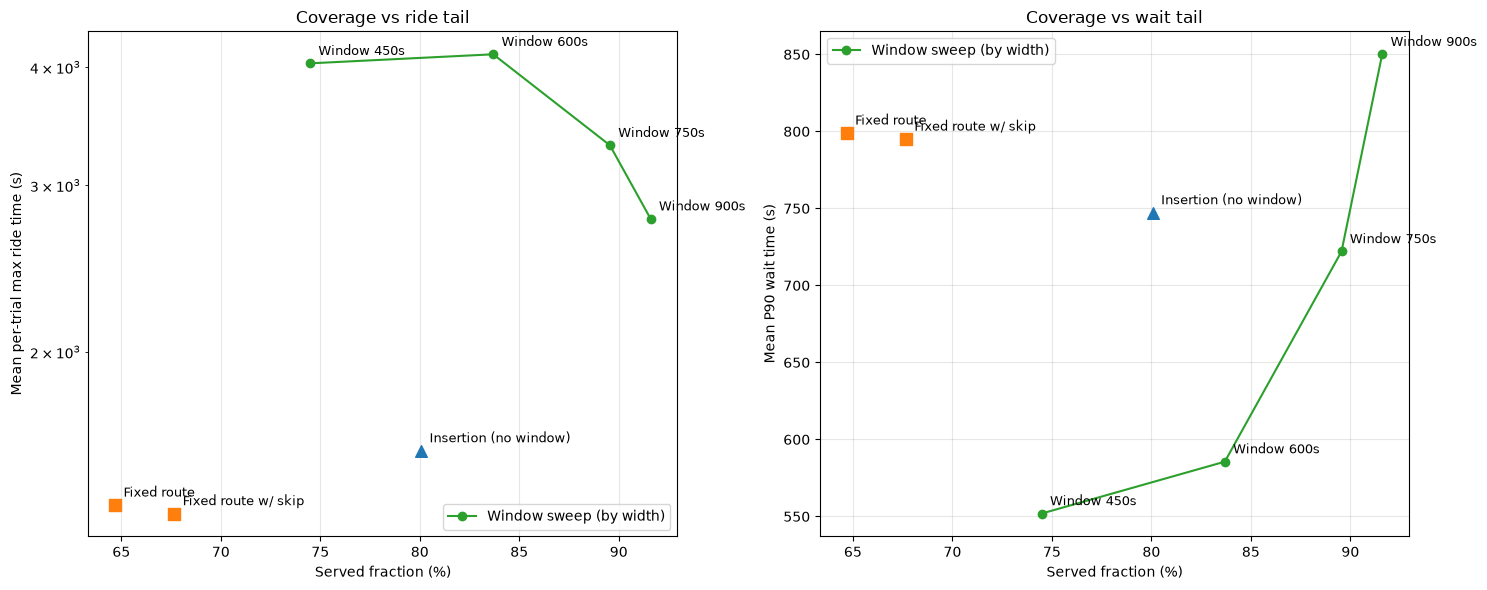

In [4]:
def _mean_of(trials, extract):
    """Mean of extract() over trials, skipping runs where it is undefined."""
    values = [v for v in (extract(t) for t in trials) if v is not None]
    return statistics.fmean(values) if values else None


def _mean_served(trials):
    """Mean served fraction, as a percentage."""
    value = _mean_of(trials, lambda t: t.kpi.served_fraction)
    return None if value is None else value * 100.0


def _mean_max_ride(trials):
    """Mean of each trial's worst ride time."""
    return _mean_of(
        trials, lambda t: max(t.ride_times) if t.ride_times else None
    )


def _mean_p90_wait(trials):
    """Mean P90 wait time."""
    return _mean_of(trials, lambda t: t.kpi.p90_wait_time)


window_labels = [f"Window {int(w)}s" for w in WINDOWS]
baseline_labels = [
    label for label in summary.results if label not in window_labels
]


def draw_frontier(ax, y_extract, ylabel, title, log_y=False):
    """Scatter every policy, joining the swept-window points in order."""
    served = {
        label: _mean_served(trials)
        for label, trials in summary.results.items()
    }
    y = {
        label: y_extract(trials)
        for label, trials in summary.results.items()
    }
    plottable = [
        label for label in summary.results
        if served[label] is not None and y[label] is not None
    ]

    swept = [label for label in window_labels if label in plottable]
    ax.plot(
        [served[label] for label in swept],
        [y[label] for label in swept],
        "-o", color="tab:green", label="Window sweep (by width)", zorder=2,
    )
    for label in (label for label in baseline_labels if label in plottable):
        marker = "^" if label.startswith("Insertion") else "s"
        colour = "tab:blue" if label.startswith("Insertion") else "tab:orange"
        ax.scatter(
            served[label], y[label], marker=marker, color=colour,
            s=70, zorder=3,
        )
    for label in plottable:
        ax.annotate(
            label, (served[label], y[label]),
            textcoords="offset points", xytext=(6, 6), fontsize=9,
        )

    if log_y:
        ax.set_yscale("log")
    ax.set_xlabel("Served fraction (%)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()


fig, (left, right) = plt.subplots(1, 2, figsize=(15, 6))
draw_frontier(
    left, _mean_max_ride, "Mean per-trial max ride time (s)",
    "Coverage vs ride tail", log_y=True,
)
draw_frontier(
    right, _mean_p90_wait, "Mean P90 wait time (s)",
    "Coverage vs wait tail",
)
plt.tight_layout()
plt.show()

## 4. Aggregate KPIs and wait distributions

`plot_kpi_bars` gives the means with ±1σ error bars; `plot_wait_distribution`
pools every fulfilled request across all trials so the **shape** of the wait
distribution is visible, not just its mean. A policy can win on mean wait and
still have an ugly tail — the box plot is where that shows up.

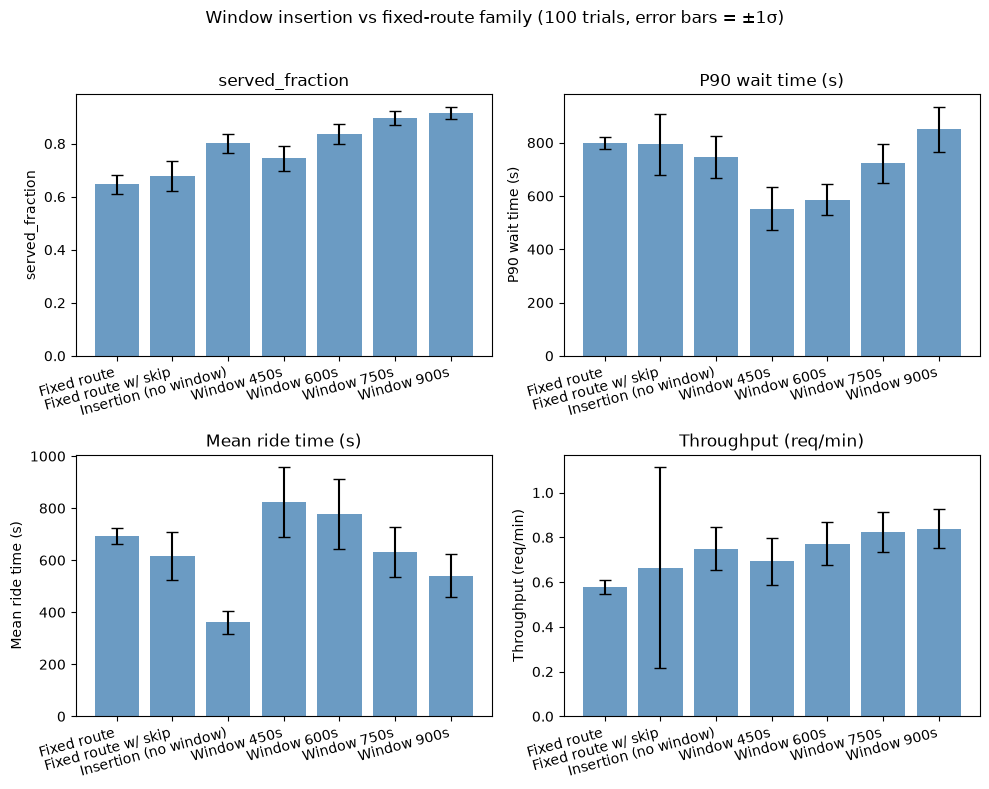

In [5]:
fig = plot_kpi_bars(
    summary.results,
    fields=["served_fraction", "p90_wait_time", "mean_ride_time", "throughput"],
    title=f"Window insertion vs fixed-route family "
          f"({N_TRIALS} trials, error bars = ±1σ)",
)

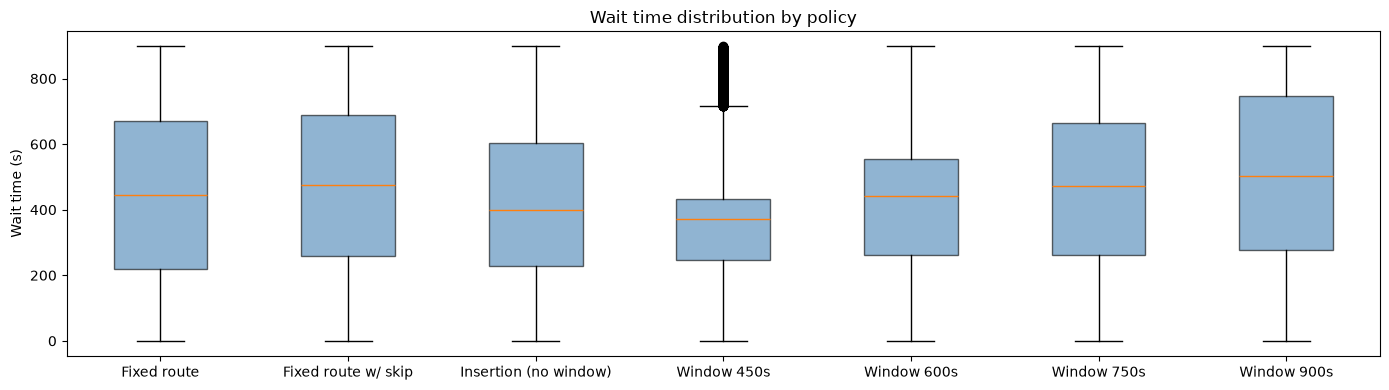

In [6]:
fig = plot_wait_distribution(summary.results)

## Reading the results

- **The ablation column (`Insertion (no window)`) is the control.** Any gap
  between it and the baselines comes from persistent insertion scheduling —
  optimising the *visit order* itself rather than bolting a constraint onto a
  fixed order. Any gap between it and the windowed columns comes from the
  deadline test.
- **Tighter windows should trade coverage for the tail.** If P90 wait falls as
  the window narrows while served fraction falls too, the knob is doing exactly
  what it should, and the choice of window is a policy decision about which
  matters more.
- **Watch the widest window.** At 900s the window equals the abandonment
  threshold, so it should accept the most and post the highest served fraction,
  at the cost of the worst wait tail among the windowed columns.
- **If a window column sits at or right of skip-stop on served fraction *and*
  below it on P90 wait**, that is a strict improvement over our previous leader
  rather than a repositioning along the old frontier.

### A caveat on reproducibility

Re-running this notebook in a fresh kernel can produce slightly different
numbers even with the seeds fixed. Python randomizes string hashing per
process, and several policies break ties with `min()` over a `set[str]` —
`FixedRoutePolicy` generates a different cycle from the same graph run to run.
Set `PYTHONHASHSEED=0` in the environment before launching Jupyter if you need
bit-reproducible output across sessions. Trial *averages* are unaffected in any
meaningful way; individual seeded numbers are not.

### Next steps

```python
# Does the window still pay off under heavier demand?
summary_heavy = summarize_comparison(
    policies=policies, graph=graph, n_trials=50, base_seed=0,
    max_requests=500, capacity=40, max_wait_s=900.0,
)

# Plan pessimistically, as you would with unpredictable CARLA travel times:
summary_cautious = summarize_comparison(
    policies=[
        ("Window 900s", lambda g: WindowInsertionPolicy(g, max_wait_s=900.0)),
        ("Window 900s (safe)",
         lambda g: WindowInsertionPolicy(
             g, max_wait_s=900.0, safety_factor=1.25)),
    ],
    graph=graph, n_trials=50, base_seed=0, **TRIAL_KWARGS,
)

# What does a real dwell time at each stop cost?
summary_dwell = summarize_comparison(
    policies=policies, graph=graph, n_trials=50, base_seed=0,
    max_requests=200, capacity=40, max_wait_s=900.0, dwell_s=20.0,
)
```

Note that the `dwell_s` example needs the policy to know about the dwell too,
or its projections will run ahead of the bus — pass a matching
`GraphTravelModel(g, dwell_s=20.0)` as the policy's `travel_model`.